# 9. Fuga de información y mejoras de los datos

## ¿Qué es la fuga de información (*data leakage*)?
Ocurre cuando, al entrenar o preparar los datos, se usa **información del conjunto de prueba**. El resultado es una evaluación **optimista**: el modelo parece mejor de lo que será con datos realmente nuevos.

En los cuadernos 1 y 3 se hicieron estos cálculos **con los 891 pasajeros, antes de separar entrenamiento y prueba**:

| Paso | Cuaderno | Información de prueba que se filtra |
|---|---|---|
| Mediana de edad por título para imputar | 1 | Las edades de los pasajeros de prueba influyen en la imputación |
| Moda de `Embarked` | 1 | Mínima |
| `TicketGroupSize` (pasajeros por boleto) | 3 | Cuenta pasajeros de prueba que comparten boleto con los de entrenamiento |
| `FarePerPerson` | 3 | Depende de `TicketGroupSize` |

Los cuadernos 4 y 6 usaron esos datos. El pipeline del cuaderno 5 ya lo hace **correctamente** porque `TitanicFeatures` aprende sus valores **solo dentro del entrenamiento de cada pliegue**.

## Plan
Comparamos los 11 modelos con validación cruzada repetida (10 × 5, **los mismos 50 pliegues** del cuaderno 6) en tres escenarios:

| Escenario | Descripción |
|---|---|
| **A. Con fuga** | Variables calculadas con todo el dataset (cuadernos 1, 3, 4 y 6) |
| **B. Sin fuga** | Pipeline: limpieza y variables se aprenden dentro de cada pliegue |
| **C. Sin fuga + mejoras** | B + las dos correcciones que encontró SHAP en el cuaderno 8 |

**Mejoras de C** (encontradas con SHAP):
1. **Títulos raros:** el grupo "Rare" mezclaba mujeres (Lady, Countess, una doctora) con hombres (Dr, Rev, Col…). Las mujeres pasan a "Mrs" y "Rare" queda solo para hombres. (Corrige el caso del Dr. Minahan.)
2. **Tarifa 0:** 15 pasajeros tienen tarifa 0 (boletos especiales, p. ej. empleados de la naviera). Se crea la bandera `FareZero` y la tarifa se imputa con la mediana de su clase, para no confundir "boleto especial" con "muy pobre".

In [1]:
import warnings
warnings.filterwarnings("ignore")

import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import clone
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.metrics import roc_auc_score, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from titanic_features import TitanicFeatures, CAT_FEATURES

sns.set_theme(style="whitegrid", palette="Set2")
SEED = 42

## 9.1 Datos: misma partición 80/20 que todos los cuadernos

In [2]:
raw = pd.read_csv("data/titanic.csv")
X_raw = raw.drop(columns="Survived")
y = raw["Survived"]

feats = pd.read_csv("data/titanic_features.csv")          # escenario A (con fuga)
X_feat = feats.drop(columns="Survived")

Xr_train, Xr_test, y_train, y_test = train_test_split(X_raw, y, test_size=0.2, stratify=y, random_state=SEED)
Xf_train, Xf_test, yf_train, _ = train_test_split(X_feat, feats["Survived"], test_size=0.2, stratify=feats["Survived"], random_state=SEED)

assert (Xr_train.index == Xf_train.index).all() and (y_train.values == yf_train.values).all()
print("Misma partición en ambos formatos:", Xr_train.shape, Xf_train.shape)

Misma partición en ambos formatos: (712, 11) (712, 35)


## 9.2 Modelos y pipelines

In [3]:
def modelos_base():
    return {
        "Regresión Logística": LogisticRegression(max_iter=2000, random_state=SEED),
        "SVC":                 SVC(probability=True, random_state=SEED),
        "Decision Tree":       DecisionTreeClassifier(max_depth=5, random_state=SEED),
        "KNeighbors":          KNeighborsClassifier(n_neighbors=7),
        "Random Forest":       RandomForestClassifier(n_estimators=300, max_depth=7, random_state=SEED, n_jobs=1),
        "AdaBoost":            AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=SEED),
        "Gradient Boosting":   GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=SEED),
        "CatBoost":            CatBoostClassifier(iterations=400, depth=5, learning_rate=0.05, verbose=0,
                                                  random_seed=SEED, allow_writing_files=False, thread_count=1),
        "XGBoost":             XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.9,
                                             colsample_bytree=0.9, eval_metric="logloss", random_state=SEED, n_jobs=1),
        "LightGBM":            LGBMClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, num_leaves=15,
                                              random_state=SEED, verbose=-1, n_jobs=1),
        "GaussianNB":          GaussianNB(),
    }

def pipeline_crudo(modelo, mejoras):
    tf = TitanicFeatures(split_rare=mejoras, fare_zero=mejoras)
    prep = ColumnTransformer([
        ("num", StandardScaler(), tf.get_num_features()),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
    ])
    return Pipeline([("features", tf), ("prep", prep), ("model", modelo)])

escenarios = {
    "A. Con fuga":            ({n: make_pipeline(StandardScaler(), m) for n, m in modelos_base().items()}, Xf_train),
    "B. Sin fuga":            ({n: pipeline_crudo(m, False) for n, m in modelos_base().items()}, Xr_train),
    "C. Sin fuga + mejoras":  ({n: pipeline_crudo(m, True) for n, m in modelos_base().items()}, Xr_train),
}

## 9.3 Validación cruzada repetida en los tres escenarios
Mismos 50 pliegues para todos: las comparaciones son **pareadas**.

In [4]:
K, N_REP = 5, 10
rcv = RepeatedStratifiedKFold(n_splits=K, n_repeats=N_REP, random_state=SEED)

auc = {}
for esc, (mods, Xtr) in escenarios.items():
    auc[esc] = {}
    for nombre, mod in mods.items():
        auc[esc][nombre] = cross_validate(mod, Xtr, y_train, cv=rcv, scoring="roc_auc", n_jobs=-1)["test_score"]
    print(f"{esc} listo")

medias = pd.DataFrame({esc: {m: v.mean() for m, v in d.items()} for esc, d in auc.items()})
medias["Efecto fuga (A−B)"] = medias["A. Con fuga"] - medias["B. Sin fuga"]
medias["Efecto mejoras (C−B)"] = medias["C. Sin fuga + mejoras"] - medias["B. Sin fuga"]
medias = medias.sort_values("C. Sin fuga + mejoras", ascending=False)
medias.to_csv("results/fuga_y_mejoras.csv")
medias.round(4)

A. Con fuga listo


B. Sin fuga listo


C. Sin fuga + mejoras listo


,A. Con fuga,B. Sin fuga,C. Sin fuga + mejoras,Efecto fuga (A−B),Efecto mejoras (C−B)
Gradient Boosting,0.8915,0.8840,0.8863,0.0075,0.0023
XGBoost,0.8893,0.8819,0.8797,0.0075,-0.0021
CatBoost,0.8846,0.8784,0.8790,0.0062,0.0006
Random Forest,0.8837,0.8770,0.8759,0.0067,-0.0011
LightGBM,0.8844,0.8764,0.8737,0.0079,-0.0027
AdaBoost,0.8768,0.8720,0.8726,0.0049,0.0007
Regresión Logística,0.8615,0.8642,0.8678,-0.0027,0.0037
SVC,0.8634,0.8595,0.8616,0.0039,0.0021
KNeighbors,0.8411,0.8471,0.8483,-0.0060,0.0012
Decision Tree,0.8493,0.8427,0.8410,0.0065,-0.0018


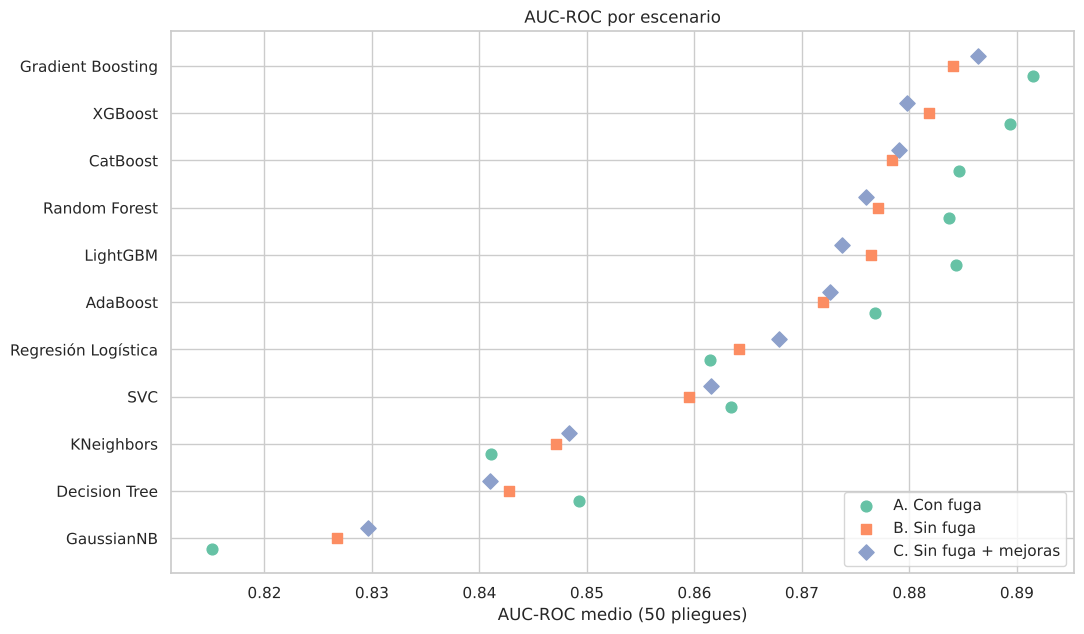

In [5]:
fig, ax = plt.subplots(figsize=(11, 6.5))
m = medias[["A. Con fuga", "B. Sin fuga", "C. Sin fuga + mejoras"]].iloc[::-1]
y_pos = np.arange(len(m))
for i, (col, mk) in enumerate(zip(m.columns, ["o", "s", "D"])):
    ax.scatter(m[col], y_pos + (i - 1) * 0.22, marker=mk, s=60, label=col)
ax.set_yticks(y_pos); ax.set_yticklabels(m.index)
ax.set_xlabel("AUC-ROC medio (50 pliegues)")
ax.set_title("AUC-ROC por escenario")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 9.4 ¿Las diferencias son significativas?
Prueba t corregida de Nadeau y Bengio (cuaderno 6) para cada modelo:
- **Fuga:** A vs B, ¿la evaluación con fuga era optimista?
- **Mejoras:** C vs B, ¿las correcciones ayudan?

In [6]:
def t_corregida(a, b, ratio=0.25):
    d = a - b
    n = len(d)
    t = d.mean() / np.sqrt(d.var(ddof=1) * (1 / n + ratio))
    return d.mean(), 2 * stats.t.sf(abs(t), df=n - 1)

filas = []
for mod in medias.index:
    dA, pA = t_corregida(auc["A. Con fuga"][mod], auc["B. Sin fuga"][mod])
    dC, pC = t_corregida(auc["C. Sin fuga + mejoras"][mod], auc["B. Sin fuga"][mod])
    filas.append({"modelo": mod, "A−B": dA, "p (fuga)": pA, "C−B": dC, "p (mejoras)": pC,
                  "% pliegues C > B": np.mean(auc["C. Sin fuga + mejoras"][mod] > auc["B. Sin fuga"][mod]) * 100})
pruebas = pd.DataFrame(filas).set_index("modelo")
pruebas.round(4)

,A−B,p (fuga),C−B,p (mejoras),% pliegues C > B
modelo,,,,,
Gradient Boosting,0.0075,0.2095,0.0023,0.4558,74.0
XGBoost,0.0075,0.1848,-0.0021,0.3405,34.0
CatBoost,0.0062,0.2247,0.0006,0.8121,58.0
Random Forest,0.0067,0.1187,-0.0011,0.6472,36.0
LightGBM,0.0079,0.2199,-0.0027,0.3839,32.0
AdaBoost,0.0049,0.2436,0.0007,0.8510,48.0
Regresión Logística,-0.0027,0.5840,0.0037,0.0388,88.0
SVC,0.0039,0.6324,0.0021,0.4297,62.0
KNeighbors,-0.0060,0.5284,0.0012,0.5391,64.0


In [7]:
ranking = medias[["A. Con fuga", "B. Sin fuga", "C. Sin fuga + mejoras"]].rank(ascending=False).astype(int)
print("Lugar de cada modelo en cada escenario:")
ranking.sort_values("C. Sin fuga + mejoras")

Lugar de cada modelo en cada escenario:


,A. Con fuga,B. Sin fuga,C. Sin fuga + mejoras
Gradient Boosting,1,1,1
XGBoost,2,2,2
CatBoost,3,3,3
Random Forest,5,4,4
LightGBM,4,5,5
AdaBoost,6,6,6
Regresión Logística,8,7,7
SVC,7,8,8
KNeighbors,10,9,9
Decision Tree,9,10,10


## 9.5 Modelo final: mejor modelo del escenario elegido, con ajuste de hiperparámetros
**Regla de decisión:** se adoptan las mejoras (C) solo si el mejor modelo de C tiene un AUC medio **mayor o igual** que el mejor modelo de B.

In [8]:
mejor_B = medias["B. Sin fuga"].idxmax()
mejor_C = medias["C. Sin fuga + mejoras"].idxmax()
usar_mejoras = medias.loc[mejor_C, "C. Sin fuga + mejoras"] >= medias.loc[mejor_B, "B. Sin fuga"]
mejor = mejor_C if usar_mejoras else mejor_B
print(f"Mejor en B: {mejor_B} ({medias.loc[mejor_B, 'B. Sin fuga']:.4f})")
print(f"Mejor en C: {mejor_C} ({medias.loc[mejor_C, 'C. Sin fuga + mejoras']:.4f})")
print(f"¿Usar mejoras? {usar_mejoras}  ->  modelo final: {mejor}")

Mejor en B: Gradient Boosting (0.8840)
Mejor en C: Gradient Boosting (0.8863)
¿Usar mejoras? True  ->  modelo final: Gradient Boosting


In [9]:
rejillas = {
    "Regresión Logística": {"model__C": [0.01, 0.1, 0.5, 1, 5, 10]},
    "SVC": {"model__C": [0.5, 1, 3, 10], "model__gamma": ["scale", 0.01, 0.05]},
    "Decision Tree": {"model__max_depth": [3, 4, 5, 6, 8], "model__min_samples_leaf": [1, 5, 10]},
    "KNeighbors": {"model__n_neighbors": [5, 7, 9, 11, 15], "model__weights": ["uniform", "distance"]},
    "Random Forest": {"model__n_estimators": [300, 500], "model__max_depth": [5, 7, 9], "model__min_samples_leaf": [1, 3]},
    "AdaBoost": {"model__n_estimators": [100, 200, 400], "model__learning_rate": [0.1, 0.5, 1.0]},
    "Gradient Boosting": {"model__n_estimators": [100, 200, 300], "model__max_depth": [2, 3, 4], "model__learning_rate": [0.03, 0.05, 0.1]},
    "CatBoost": {"model__iterations": [300, 500], "model__depth": [4, 5, 6], "model__learning_rate": [0.03, 0.05]},
    "XGBoost": {"model__n_estimators": [200, 300, 500], "model__max_depth": [3, 4, 5], "model__learning_rate": [0.03, 0.05]},
    "LightGBM": {"model__n_estimators": [200, 300, 500], "model__max_depth": [3, 4, 5], "model__learning_rate": [0.03, 0.05], "model__num_leaves": [7, 15]},
    "GaussianNB": {"model__var_smoothing": [1e-9, 1e-8, 1e-7]},
}
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
busqueda = GridSearchCV(pipeline_crudo(modelos_base()[mejor], usar_mejoras), rejillas[mejor], cv=cv5, scoring="roc_auc", n_jobs=-1)
busqueda.fit(Xr_train, y_train)
print("Mejores hiperparámetros:", busqueda.best_params_)
print("AUC-ROC en validación cruzada:", round(busqueda.best_score_, 4))
v2 = busqueda.best_estimator_

Mejores hiperparámetros: {'model__learning_rate': 0.03, 'model__max_depth': 4, 'model__n_estimators': 200}
AUC-ROC en validación cruzada: 0.8964


## 9.6 Umbral de decisión del modelo nuevo (mismo método del cuaderno 7)

In [10]:
def metricas(y_real, proba, u):
    pred = (proba >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    sens, esp = tp / (tp + fn), tn / (tn + fp)
    prec = tp / (tp + fp) if tp + fp else 0
    return {"umbral": u, "exactitud": (tp + tn) / len(y_real), "precision": prec, "sensibilidad": sens,
            "especificidad": esp, "f1": 2 * prec * sens / (prec + sens) if prec + sens else 0,
            "youden_J": sens + esp - 1, "TP": tp, "FN": fn, "TN": tn, "FP": fp}

umbrales = np.round(np.arange(0.05, 0.96, 0.01), 2)
youden = []
for s in range(10):
    p = cross_val_predict(clone(v2), Xr_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=s),
                          method="predict_proba", n_jobs=-1)[:, 1]
    youden.append(pd.DataFrame([metricas(y_train, p, u) for u in umbrales]).set_index("umbral")["youden_J"].idxmax())
umbral_v2 = float(np.round(np.median(youden), 2))
print("Umbral de Youden en 10 repeticiones:", youden)
print("Umbral elegido (mediana):", umbral_v2)

Umbral de Youden en 10 repeticiones: [np.float64(0.46), np.float64(0.27), np.float64(0.35), np.float64(0.44), np.float64(0.33), np.float64(0.31), np.float64(0.23), np.float64(0.25), np.float64(0.37), np.float64(0.23)]
Umbral elegido (mediana): 0.32


## 9.7 Comparación final en el conjunto de prueba: modelo anterior (v1) vs nuevo (v2)

In [11]:
v1 = clone(joblib.load("models/titanic_pipeline.joblib")).fit(Xr_train, y_train)
umbral_v1 = float(open("results/umbral.txt").read())
v2_fit = clone(v2).fit(Xr_train, y_train)

p1, p2 = v1.predict_proba(Xr_test)[:, 1], v2_fit.predict_proba(Xr_test)[:, 1]
final = pd.DataFrame({
    f"v1 (cuadernos 5 y 7, umbral {umbral_v1})": {**metricas(y_test, p1, umbral_v1), "auc_roc": roc_auc_score(y_test, p1)},
    f"v2 (este cuaderno, umbral {umbral_v2})": {**metricas(y_test, p2, umbral_v2), "auc_roc": roc_auc_score(y_test, p2)},
}).T[["umbral", "auc_roc", "exactitud", "precision", "sensibilidad", "especificidad", "f1", "TP", "FN", "TN", "FP"]]
final.to_csv("results/v1_vs_v2_prueba.csv")
final.astype(float).round(3)

,umbral,auc_roc,exactitud,precision,sensibilidad,especificidad,f1,TP,FN,TN,FP
"v1 (cuadernos 5 y 7, umbral 0.32)",0.32,0.85,0.793,0.705,0.797,0.791,0.748,55.0,14.0,87.0,23.0
"v2 (este cuaderno, umbral 0.32)",0.32,0.86,0.788,0.696,0.797,0.782,0.743,55.0,14.0,86.0,24.0


## 9.8 ¿Se corrigieron los casos que encontró SHAP?

In [12]:
casos = raw.loc[raw["Name"].str.contains("Minahan, Dr|Tornquist|Lady|Countess|Dr. Alice", regex=True)]
casos_test = casos[casos.index.isin(Xr_test.index)]
casos_all = casos.copy()
casos_all["en_prueba"] = casos_all.index.isin(Xr_test.index)
casos_all["prob_v1"] = v1.predict_proba(casos_all[X_raw.columns])[:, 1].round(3)
casos_all["prob_v2"] = v2_fit.predict_proba(casos_all[X_raw.columns])[:, 1].round(3)
casos_all[["Name", "Sex", "Age", "Pclass", "Fare", "Survived", "en_prueba", "prob_v1", "prob_v2"]]

,Name,Sex,Age,Pclass,Fare,Survived,en_prueba,prob_v1,prob_v2
245,"Minahan, Dr. William Edward",male,44.0,1,90.0000,0,True,0.990,0.994
271,"Tornquist, Mr. William Henry",male,25.0,3,0.0000,1,True,0.030,0.054
556,"Duff Gordon, Lady. (Lucille Christiana Sutherl...",female,48.0,1,39.6000,1,False,0.926,0.962
759,"Rothes, the Countess. of (Lucy Noel Martha Dye...",female,33.0,1,86.5000,1,True,0.960,0.972
796,"Leader, Dr. Alice (Farnham)",female,49.0,1,25.9292,1,False,0.896,0.932


In [13]:
zero = raw[raw["Fare"] == 0]
print(f"Pasajeros con tarifa 0: {len(zero)}  |  sobrevivieron: {zero['Survived'].sum()} ({zero['Survived'].mean():.0%})")
print(f"Tasa general de supervivencia: {raw['Survived'].mean():.0%}")

Pasajeros con tarifa 0: 15  |  sobrevivieron: 1 (7%)
Tasa general de supervivencia: 38%


## 9.9 Guardar el modelo final

In [14]:
if usar_mejoras:
    final_model = clone(v2).fit(X_raw, y)
    joblib.dump(final_model, "models/titanic_pipeline_v2.joblib")
    open("results/umbral_v2.txt", "w").write(str(umbral_v2))
    open("results/modelo_final.txt", "w").write("v2")
    print("Guardado models/titanic_pipeline_v2.joblib, umbral", umbral_v2, "-> app.py usará v2")
else:
    open("results/modelo_final.txt", "w").write("v1")
    print("Las mejoras no superaron a v1; app.py sigue usando v1")

Guardado models/titanic_pipeline_v2.joblib, umbral 0.32 -> app.py usará v2


## 9.10 Conclusiones

### 1. La fuga de información existía, pero su efecto fue pequeño y no significativo
- En los modelos de árboles, la evaluación con fuga (A) daba un AUC **0.005–0.008 más alto** que la evaluación correcta (B). Es decir, era **ligeramente optimista**, como se esperaba.
- Ninguna de esas diferencias es estadísticamente significativa (p entre 0.12 y 0.24 con la prueba corregida).
- **El ranking prácticamente no cambia:** Gradient Boosting es 1.º en los tres escenarios, seguido de XGBoost y CatBoost.
- **Conclusión:** las conclusiones de los cuadernos 4 y 6 **siguen siendo válidas**; la fuga solo infló un poco los números. Aun así, la forma correcta es la del pipeline (B y C), y es la que se usa en el modelo final.

> Nota: A y B no difieren solo en la fuga, también en algunas variables (A tiene `LogFare`, `TicketGroupSize` y `AgeWasMissing`). Por eso en Naive Bayes y KNN la versión sin fuga salió *mejor*: esos modelos se perjudican con variables redundantes.

### 2. Las mejoras de SHAP ayudaron poco
| Modelo | Cambio de AUC (C − B) | ¿Significativo? |
|---|---|---|
| Gradient Boosting | +0.0023 (gana en 74 % de pliegues) | No (p = 0.46) |
| Regresión Logística | +0.0037 (gana en 88 % de pliegues) | **Sí (p = 0.039)** |
| XGBoost / LightGBM | −0.002 a −0.003 | No |

Solo la Regresión Logística mejora de forma significativa: los modelos lineales no pueden "descubrir" solos que una tarifa de 0 es especial, así que la bandera `FareZero` les ayuda. Los modelos de árboles ya lo detectaban por su cuenta.

### 3. Lo que aprendimos de los dos casos de SHAP (más importante que el número)
- **Tarifa 0 (Tornquist):** de los 15 pasajeros con tarifa 0, **solo 1 sobrevivió (7 % vs 38 % general)**. La tarifa 0 **no era un error de datos**: es una señal real de que esos pasajeros (boletos de la naviera) casi no se salvaron. Tornquist fue la **excepción**, y ningún modelo razonable debería predecir que sobrevive. El modelo nuevo sube su probabilidad de 3 % a 5 %, pero sigue prediciendo "no sobrevive", y eso es lo correcto.
- **Títulos raros (Dr. Minahan):** separar a las mujeres del grupo "Rare" fue correcto (Lady, Countess y la Dra. Leader ahora tienen probabilidades más altas y bien clasificadas), pero **no corrigió a Minahan** (99 %). Revisando el entrenamiento, **5 de 9 hombres con título raro en 1.ª clase sobrevivieron (56 %)**, contra 33 % de los "Mr" de 1.ª clase. El modelo aprendió un patrón **real pero de un grupo de solo 9 personas**, y por eso es **demasiado confiado**. No es un error de datos: es el límite de aprender de pocos ejemplos.

### 4. Modelo final
Se adopta el **modelo v2** (sin fuga + mejoras, Gradient Boosting con `learning_rate=0.03`, `max_depth=4`, `n_estimators=200`, umbral 0.32) porque tiene el mejor AUC en validación cruzada (**0.896**) y es metodológicamente más limpio. En prueba es **prácticamente igual a v1** (AUC 0.86 vs 0.85; exactitud 0.788 vs 0.793; misma sensibilidad 0.797). **Las diferencias entre v1 y v2 no son significativas.** Se elige v2 por ser más correcto, no por ser mejor en números.

`app.py` ahora usa `models/titanic_pipeline_v2.joblib` con su umbral (`results/modelo_final.txt` indica la versión).

### Lección general
**No toda "mejora" lógica mejora el modelo.** Hay que medirla con validación cruzada y una prueba estadística antes de adoptarla. Y SHAP sirve tanto para encontrar problemas como para descubrir que algo que parecía un error en realidad era un patrón real.